
--- Running Secure Channel on Processor A ---
Average Circuit Depth: 2.72
Average Gate Count: 2.72
Calculated QBER: 0.00%
Sifted Key Length: 770 bits

--- Running Secure Channel on Processor B ---
Average Circuit Depth: 2.72
Average Gate Count: 2.72
Calculated QBER: 0.00%
Sifted Key Length: 770 bits

Original Secret Message: 'Hello Bob! This is a fully quantum-secure communication channel.'
Successfully Decrypted Message: 'Hello Bob! This is a fully quantum-secure communication channel.'


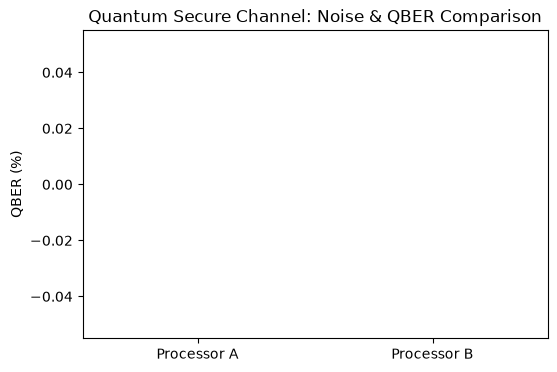

In [1]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from src.qkd import generate_bb84_job, calculate_qber, encrypt_message, decrypt_message
from processors.hardware import processor_a, processor_b
import matplotlib.pyplot as plt
import os

# 1. Generate BB84 protocol circuits with enough bits for encryption
n_bits = 1500
circuits, alice_bits, alice_bases, bob_bases = generate_bb84_job(n_bits=n_bits)

def run_processor_experiment(processor, name):
    print(f"\n--- Running Secure Channel on {name} ---")
    backend = processor["backend"]
    noise_model = processor["noise_model"]
    
    sim = AerSimulator(noise_model=noise_model)
    
    bob_results = []
    total_depth = 0
    total_gates = 0
    
    for qc in circuits:
        transpiled_qc = transpile(qc, backend=backend, optimization_level=1)
        total_depth += transpiled_qc.depth()
        total_gates += transpiled_qc.size()
        
        job = sim.run(transpiled_qc, shots=1, memory=True)
        result = job.result()
        measured_bit = result.get_memory()[0]
        bob_results.append(measured_bit)
        
    qber, key_a, key_b = calculate_qber(alice_bits, alice_bases, bob_bases, bob_results)
    
    print(f"Average Circuit Depth: {total_depth / n_bits:.2f}")
    print(f"Average Gate Count: {total_gates / n_bits:.2f}")
    print(f"Calculated QBER: {qber * 100:.2f}%")
    print(f"Sifted Key Length: {len(key_a)} bits")
    
    return qber, key_a, key_b

# 2. Run simulation across both processors
qber_a, key_a_alice, key_a_bob = run_processor_experiment(processor_a, "Processor A")
qber_b, key_b_alice, key_b_bob = run_processor_experiment(processor_b, "Processor B")

# 3. Transmit an actual encrypted secret message using Processor A's quantum key
secret_message = "Hello Bob! This is a fully quantum-secure communication channel."
print(f"\nOriginal Secret Message: '{secret_message}'")

ciphertext, msg_len = encrypt_message(secret_message, key_a_alice)
received_message = decrypt_message(ciphertext, key_a_bob, msg_len)
print(f"Successfully Decrypted Message: '{received_message}'")

# 4. Automatically create folder if missing, then save the comparison plot
os.makedirs("results/figures", exist_ok=True)

plt.figure(figsize=(6, 4))
plt.bar(["Processor A", "Processor B"], [qber_a * 100, qber_b * 100], color=['#2b5c8f', '#d9534f'])
plt.ylabel("QBER (%)")
plt.title("Quantum Secure Channel: Noise & QBER Comparison")
plt.savefig("results/figures/qber_comparison.png")
plt.show()

In [2]:
import pandas as pd
import os

# Create directory if it doesn't exist
os.makedirs("results/tables", exist_ok=True)

# Compile results into a DataFrame
metrics_data = {
    "Processor": ["Processor A", "Processor B"],
    "QBER (%)": [qber_a * 100, qber_b * 100],
    "Sifted Key Length (bits)": [len(key_a_alice), len(key_b_alice)]
}

df = pd.DataFrame(metrics_data)
df.to_csv("results/tables/metrics.csv", index=False)
print("Metrics successfully exported to results/tables/metrics.csv!")
display(df)

Metrics successfully exported to results/tables/metrics.csv!


,Processor,QBER (%),Sifted Key Length (bits)
0,Processor A,0.0,770
1,Processor B,0.0,770


In [ ]:
def text_to_bits(text):
    return ''.join(format(ord(c), '08b') for c in text)

def bits_to_text(bits):
    chars = [bits[i:i+8] for i in range(0, len(bits), 8)]
    return ''.join(chr(int(c, 2)) for c in chars)

# Prompt user for a secret message
user_message = input("Enter a secret message to encrypt: ")
message_bits = text_to_bits(user_message)

# Use Alice's sifted key
sifted_key = "".join(map(str, key_a_alice))

if len(sifted_key) < len(message_bits):
    print(f"Error: Message requires {len(message_bits)} bits, but key is only {len(sifted_key)} bits.")
else:
    # Encrypt using XOR
    ciphertext = "".join(str(int(b) ^ int(k)) for b, k in zip(message_bits, sifted_key))
    print(f"\n[Ciphertext Sent]: {ciphertext[:32]}... (truncated)")

    # Decrypt using Bob's key
    bob_key = "".join(map(str, key_b_alice))
    decrypted_bits = "".join(str(int(c) ^ int(k)) for c, k in zip(ciphertext, bob_key))
    decrypted_message = bits_to_text(decrypted_bits)
    
    print(f"[Decrypted Message]: {decrypted_message}")